# ResNet18 迁移学习：六类动物图像分类

本 Notebook 展示已经完成的 CNN 方法。模型使用 torchvision 的 ImageNet-1K 预训练 ResNet18，将最后的全连接层替换为六分类输出。训练分为两个阶段：先冻结卷积骨干训练分类头，再解冻全部参数，以较小学习率微调；最佳模型按验证集 Macro F1 保存，测试集不参与训练或选模。

实现参考 PyTorch 官方开源项目中的 [Transfer Learning for Computer Vision Tutorial](https://github.com/pytorch/tutorials/blob/main/beginner_source/transfer_learning_tutorial.py) 和 [ResNet18 权重文档](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18.html)。项目代码是针对本数据清单和六分类任务的独立实现。

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / 'src').exists() else cwd.parent
if not (PROJECT_ROOT / 'src').exists():
    raise RuntimeError(f'无法定位项目根目录，当前目录为 {cwd}')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display

from src.cnn.config import TrainingConfig
from src.cnn.pipeline import run_experiment
from src.comparison import build_method_comparison

print('项目根目录:', PROJECT_ROOT)
print('计算设备:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU')

项目根目录: D:\AI\animal-classification
计算设备: NVIDIA GeForce RTX 5070 Ti Laptop GPU


## 执行实验

`run_experiment` 在不存在最佳权重时执行完整的两阶段训练；已经训练完成时加载 `checkpoints/cnn/best_resnet18.pt` 并重新评估测试集，避免每次打开 Notebook 都重复训练。需要从头训练时，可传入 `force_retrain=True`。

数据集规模: {'train': 10282, 'val': 2227, 'test': 2265}
最佳 epoch: 7
最佳验证集 Macro F1: 0.9740


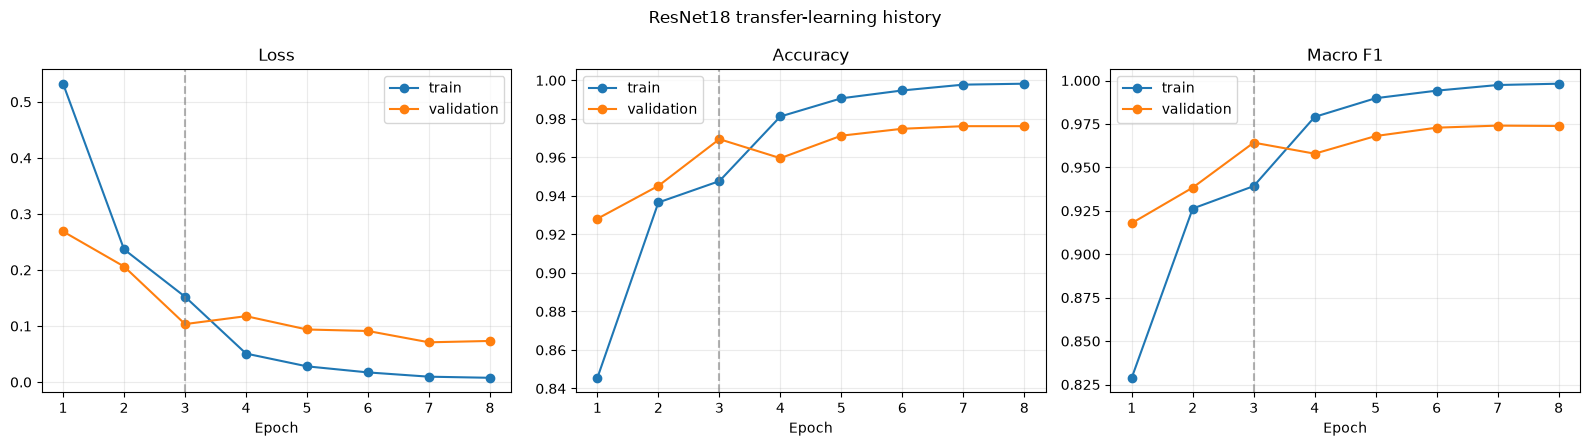

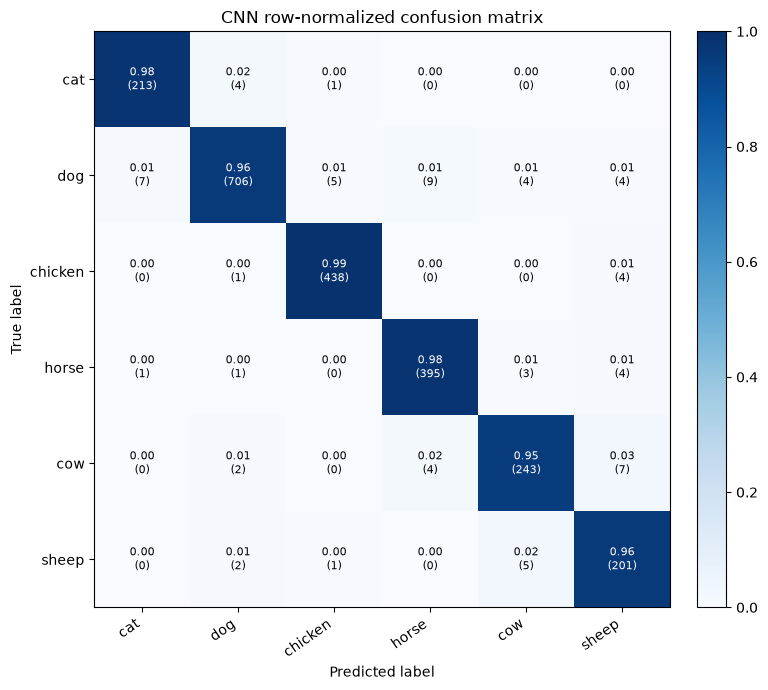

In [2]:
config = TrainingConfig(project_root=PROJECT_ROOT)
result = run_experiment(config, force_retrain=False)

print('数据集规模:', result['run_info']['dataset_sizes'])
print('最佳 epoch:', result['run_info']['best_epoch'])
print('最佳验证集 Macro F1:', f"{result['run_info']['best_val_macro_f1']:.4f}")

## 训练过程与测试结果

In [3]:
history = result['history']
display(history.style.format({
    'learning_rate': '{:.6f}', 'train_loss': '{:.4f}', 'train_accuracy': '{:.4f}',
    'train_macro_f1': '{:.4f}', 'val_loss': '{:.4f}', 'val_accuracy': '{:.4f}',
    'val_macro_f1': '{:.4f}',
}))
display(pd.DataFrame([result['summary']], index=['ResNet18 test']).style.format('{:.4f}'))
display(result['per_class'].style.format('{:.4f}'))

,epoch,stage,stage_epoch,learning_rate,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1
0,1,head,1,0.001000,0.5324,0.8456,0.8289,0.2687,0.9282,0.9179
1,2,head,2,0.000500,0.2368,0.9366,0.9263,0.2062,0.9452,0.9384
2,3,finetune,1,0.000100,0.1523,0.9477,0.9392,0.1035,0.9695,0.9642
3,4,finetune,2,0.000093,0.0509,0.9812,0.9791,0.1176,0.9596,0.9579
4,5,finetune,3,0.000075,0.0281,0.9907,0.9898,0.0938,0.9713,0.9680
5,6,finetune,4,0.000050,0.0173,0.9947,0.9942,0.0912,0.9749,0.9729
6,7,finetune,5,0.000025,0.0096,0.9978,0.9974,0.0710,0.9762,0.9740
7,8,finetune,6,0.000007,0.0077,0.9982,0.9982,0.0734,0.9762,0.9738


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Sample count
ResNet18 test,0.9695,0.9615,0.9692,0.9652,0.9696,2265.0000


,Precision,Recall,F1,Support
Class,,,,
cat,0.9638,0.9771,0.9704,218.0000
dog,0.9860,0.9605,0.9731,735.0000
chicken,0.9843,0.9887,0.9865,443.0000
horse,0.9681,0.9777,0.9729,404.0000
cow,0.9529,0.9492,0.9511,256.0000
sheep,0.9136,0.9617,0.9371,209.0000


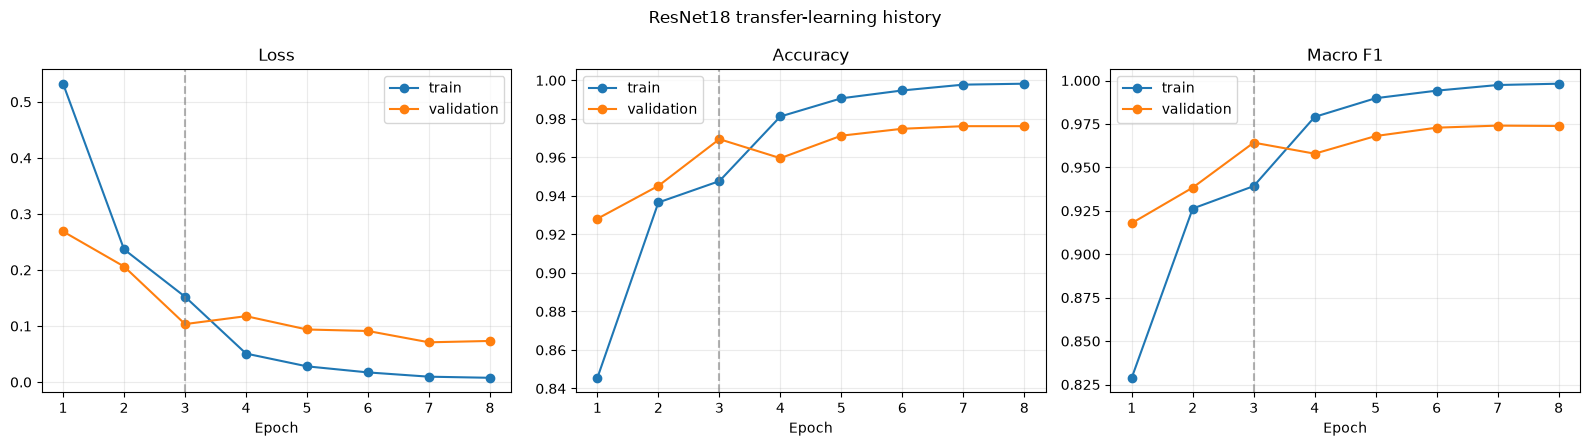

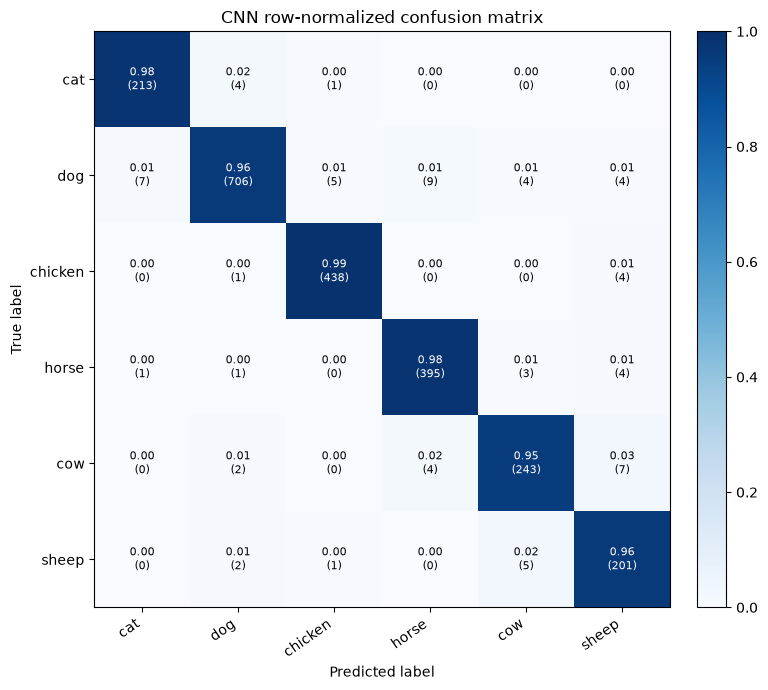

In [4]:
display(result['learning_figure'])
display(result['confusion_figure'])
plt.close('all')

## 产生式系统与 CNN 的统一比较

下表统一展示 Accuracy、Macro Precision、Macro Recall 和 Macro F1。需要注意，两种方法只有输出类别相同：产生式系统输入人工符号事实，评价集是 132 条符号压力案例；CNN 输入图片，评价集是 2,265 张保留测试图片。

,Evaluation input,Accuracy,Macro Precision,Macro Recall,Macro F1
Production system (symbolic stress test),132 manually generated symbolic cases,0.7803,1.0000,0.7803,0.8751
ResNet18 (Animals-10 image test set),"2,265 held-out animal images",0.9695,0.9615,0.9692,0.9652


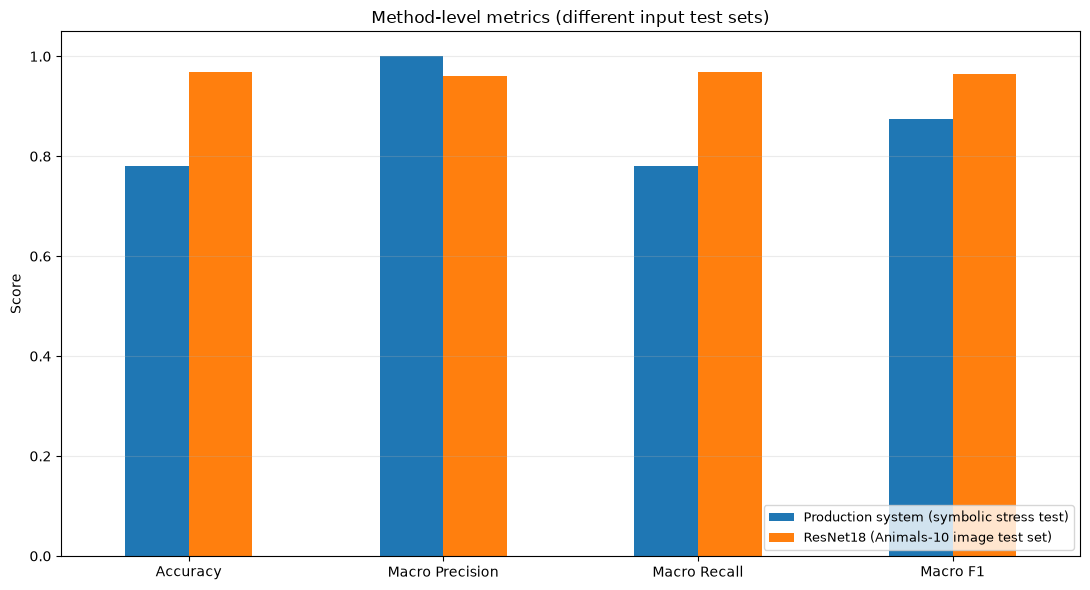

In [5]:
comparison, comparison_figure = build_method_comparison(PROJECT_ROOT)
display(comparison.style.format('{:.4f}', subset=['Accuracy', 'Macro Precision', 'Macro Recall', 'Macro F1']))
display(comparison_figure)
plt.close('all')

## 结论

ResNet18 迁移学习在真实图片测试集上提供端到端图像分类能力；产生式系统不训练、可逐步解释并能明确拒识，但依赖人工输入属性且对缺失关键事实敏感。